# Lab 6 - Autoenkodery, redukcja wymiarowości i klasteryzacja


## Cel zajęć

Na tych zajęciach przechodzimy od uczenia nadzorowanego (L3-L5) do **uczenia nienadzorowanego**. Zadajemy pytanie: *czy sieć może nauczyć się użytecznej, zwartej reprezentacji danych bez etykiet?* Porównamy klasyczne metody liniowe (PCA, SVD, LDA) z autoenkoderami (AE) w Keras i sprawdzimy, do czego takie reprezentacje się przydają: wizualizacji, kompresji, klasteryzacji, odszumiania i detekcji anomalii.

Po zajęciach student potrafi:
- zastosować PCA, TruncatedSVD i LDA do redukcji wymiarowości obrazów i zinterpretować wykres wyjaśnionej wariancji,
- zbudować i wytrenować autoenkoder gęsty i konwolucyjny w Keras (Functional API), osobno korzystać z enkodera i dekodera,
- porównać błąd rekonstrukcji AE i PCA w funkcji wymiaru przestrzeni ukrytej i wyjaśnić, dlaczego liniowy AE ≈ PCA,
- przeprowadzić klasteryzację k-means w różnych przestrzeniach cech i ocenić ją metrykami ARI, NMI, silhouette,
- wytrenować autoenkoder odszumiający oraz użyć błędu rekonstrukcji do wykrywania anomalii.

**Efekty uczenia (karta przedmiotu):** UGŁ_W01 (modele DL, metody uczenia), UGŁ_W02 (zaawansowane metody i narzędzia DL), UGŁ_U01 (stawianie i weryfikacja hipotez - np. "nieliniowy AE rekonstruuje lepiej niż PCA przy tym samym wymiarze"), UGŁ_U02 (usprawnienia w oparciu o biblioteki - AE konwolucyjny, odszumiający).

**Powiązanie z wykładem:** W5 (redukcja wymiarowości, autoenkodery, deep clustering, detekcja anomalii), W2 (splot transponowany, upsampling - "warstwy rozwijające"), W3 (funkcje straty, optymalizatory), W4 (metryki, ROC-AUC).

### Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | 0. Przygotowanie środowiska, wczytanie MNIST |
| 10-35 min | 1-2. PCA, TruncatedSVD, LDA (Zadania 2.1, 3.1) |
| 35-65 min | 4. Autoenkoder gęsty, latent 2 i 32 (Zadanie 4.1) |
| 65-85 min | 5-6. AE vs PCA w funkcji wymiaru, liniowy AE ≈ PCA (Zadania 5.1, 6.1) |
| 85-95 min | **Przerwa** |
| 95-115 min | 7. Klasteryzacja k-means: piksele / PCA / latent AE (Zadanie 7.1) |
| 115-135 min | 8. Autoenkoder odszumiający (Zadanie 8.1) |
| 135-155 min | 9. Autoenkoder konwolucyjny (Zadanie 9.1) |
| 155-170 min | 10. Detekcja anomalii (Zadanie 10.1) |
| 170-180 min | Pytania kontrolne, podsumowanie, notatki do sprawozdania |

### Wymagania wstępne
- Keras Functional API, `compile`/`fit`, callbacks (L3), warstwy `Conv2D`, `MaxPooling2D` (L4).
- Metryki klasyfikacji i ROC-AUC (L5).
- Podstawy algebry liniowej: wartości i wektory własne, rzut na podprzestrzeń.

## 0. Przygotowanie środowiska

1. W Colab wybierz **Środowisko wykonawcze -> Zmień typ środowiska -> T4 GPU** i zapisz.
2. Uruchom poniższe komórki po kolei (Shift+Enter).

Zmienna `SZYBKI_TRYB` steruje rozmiarem eksperymentów. Domyślnie (`False`) trenujemy na pełnym MNIST z sensowną liczbą epok - tak, jak należy to robić na GPU. **Jeśli pracujesz bez GPU** (np. w domu na laptopie albo gdy Colab nie przydzielił T4), ustaw `SZYBKI_TRYB = True` - zredukujemy dane do 2000 próbek i liczbę epok do 1-2. Wyniki będą wtedy słabsze, ale cały notebook przejdzie w kilka minut i zobaczysz, czy kod działa.

In [33]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")  # Keras 3 - używamy backendu TensorFlow
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| backend:", keras.backend.backend())

TensorFlow: 2.21.0 | Keras: 3.13.2 | backend: tensorflow


In [34]:
# Sprawdzenie GPU - na T4 zobaczysz jedno urządzenie 'GPU'
gpus = tf.config.list_physical_devices("GPU")
print("Dostępne GPU:", gpus if gpus else "brak - pracujesz na CPU (rozważ SZYBKI_TRYB = True)")

# Powtarzalność: ustawiamy seedy Pythona, NumPy i TF jednym wywołaniem
SEED = 42
keras.utils.set_random_seed(SEED)

# Tryb szybki: True, jeśli pracujesz bez GPU (mniej epok i danych)
SZYBKI_TRYB = False

EPOKI = 2 if SZYBKI_TRYB else 20          # główne treningi AE
EPOKI_KROTKO = 1 if SZYBKI_TRYB else 10   # treningi w pętlach (wiele modeli)
N_TRAIN = 2000 if SZYBKI_TRYB else 60000  # liczba obrazów treningowych
N_TEST = 500 if SZYBKI_TRYB else 10000    # liczba obrazów testowych
N_VIZ = 1000 if SZYBKI_TRYB else 5000     # liczba punktów na wykresach 2D / do klasteryzacji
BATCH = 256
print(f"SZYBKI_TRYB={SZYBKI_TRYB}, EPOKI={EPOKI}, N_TRAIN={N_TRAIN}")

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
SZYBKI_TRYB=False, EPOKI=20, N_TRAIN=60000


## 1. Dane: MNIST

MNIST to 70 000 obrazów 28x28 odręcznie pisanych cyfr (60 000 treningowych, 10 000 testowych). Każdy obraz to punkt w przestrzeni $\mathbb{R}^{784}$. Intuicja kluczowa dla całych zajęć: **prawdziwe obrazy cyfr zajmują maleńki, zakrzywiony fragment tej przestrzeni** (tzw. rozmaitość, ang. *manifold*). Losowy wektor 784 pikseli wygląda jak szum, a nie jak cyfra. Redukcja wymiarowości próbuje znaleźć współrzędne opisujące tę rozmaitość.

Przygotowanie:
- skalujemy piksele do $[0, 1]$ (dzielenie przez 255) - pasuje to do wyjścia `sigmoid` w dekoderze i do straty BCE/MSE,
- tworzymy wersję spłaszczoną `(N, 784)` dla PCA i AE gęstego oraz wersję `(N, 28, 28, 1)` dla AE konwolucyjnego,
- **etykiet nie używamy do uczenia** (z wyjątkiem LDA, która jest metodą nadzorowaną) - służą tylko do oceny i kolorowania wykresów.

In [35]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.mnist.load_data()

# Podzbiory zależne od trybu (w pełnym trybie - całość)
x_train = x_train_full[:N_TRAIN].astype("float32") / 255.0   # skalowanie do [0, 1]
y_train = y_train_full[:N_TRAIN]
x_test = x_test_full[:N_TEST].astype("float32") / 255.0
y_test = y_test_full[:N_TEST]

# Wersje spłaszczone (N, 784) - dla PCA, SVD, LDA i AE gęstego
x_train_flat = x_train.reshape(len(x_train), -1)
x_test_flat = x_test.reshape(len(x_test), -1)
# Wersje z kanałem (N, 28, 28, 1) - dla AE konwolucyjnego
x_train_img = x_train[..., None]
x_test_img = x_test[..., None]

print("train:", x_train_flat.shape, "test:", x_test_flat.shape, "zakres:", x_train.min(), x_train.max())

train: (60000, 784) test: (10000, 784) zakres: 0.0 1.0


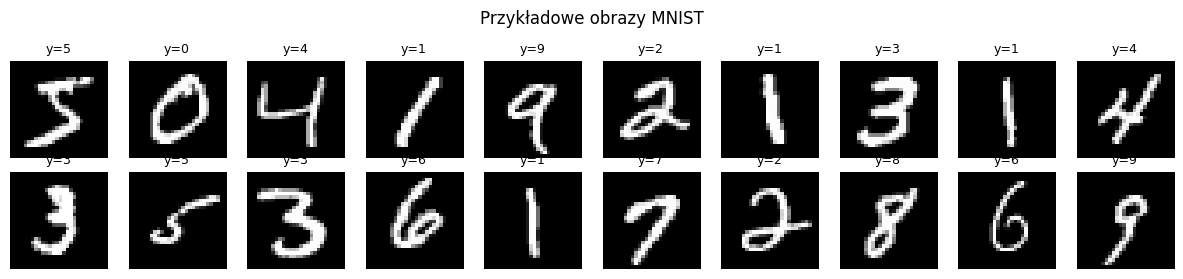

In [36]:
# Podgląd kilku obrazów z etykietami
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"y={y_train[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Przykładowe obrazy MNIST")
plt.tight_layout(); plt.show()

In [37]:
# Funkcje pomocnicze używane w całym notebooku

def mse_per_sample(x, x_hat):
    # Błąd średniokwadratowy rekonstrukcji osobno dla każdego obrazu
    x = np.asarray(x).reshape(len(x), -1)
    x_hat = np.asarray(x_hat).reshape(len(x_hat), -1)
    return np.mean((x - x_hat) ** 2, axis=1)

def pokaz_rekonstrukcje(oryginaly, rekonstrukcje, tytuly=("oryginał", "rekonstrukcja"), n=10, suptitle=""):
    # Rysuje w wierszach: oryginały i jedną lub więcej wersji rekonstrukcji
    wiersze = [oryginaly] + (list(rekonstrukcje) if isinstance(rekonstrukcje, (list, tuple)) else [rekonstrukcje])
    fig, axes = plt.subplots(len(wiersze), n, figsize=(1.2 * n, 1.3 * len(wiersze)))
    axes = np.atleast_2d(axes)
    for r, dane in enumerate(wiersze):
        for i in range(n):
            axes[r, i].imshow(np.asarray(dane[i]).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            axes[r, i].axis("off")
        axes[r, 0].set_title(tytuly[r] if r < len(tytuly) else "", fontsize=8, loc="left")
    fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

def scatter_2d(z, y, tytul, ax=None):
    # Wykres punktów 2D pokolorowanych etykietą cyfry
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    z = np.asarray(z)
    if z.shape[1] == 1:   # zabezpieczenie: metoda zwróciła tylko 1 wymiar (np. LDA na zdegenerowanych danych)
        z = np.column_stack([z[:, 0], np.random.default_rng(0).normal(scale=0.05, size=len(z))])
    sc = ax.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=4, alpha=0.7)
    ax.set_title(tytul); ax.set_xlabel("wymiar 1"); ax.set_ylabel("wymiar 2")
    ax.legend(*sc.legend_elements(), title="cyfra", fontsize=7, loc="best", markerscale=0.8)
    return ax

## 2. PCA - analiza składowych głównych

**Idea (W5):** szukamy ortonormalnych kierunków $\mathbf{w}_1, \mathbf{w}_2, \dots$, wzdłuż których dane mają największą wariancję. Po wycentrowaniu danych $\tilde X = X - \bar{\mathbf{x}}$ macierz kowariancji to
$$C = \frac{1}{N-1}\tilde X^\top \tilde X,$$
a składowe główne to jej wektory własne uporządkowane malejąco według wartości własnych $\lambda_1 \ge \lambda_2 \ge \dots$. Wartość $\lambda_j$ to wariancja danych wzdłuż $j$-tej składowej, więc **współczynnik wyjaśnionej wariancji** wynosi $\lambda_j / \sum_i \lambda_i$.

Rzut na $k$ składowych i rekonstrukcja:
$$\mathbf{z} = W_k^\top(\mathbf{x} - \bar{\mathbf{x}}), \qquad \hat{\mathbf{x}} = \bar{\mathbf{x}} + W_k \mathbf{z}.$$

PCA daje **optymalną liniową** rekonstrukcję w sensie MSE (twierdzenie Eckarta-Younga) - zapamiętaj to, wrócimy do tego przy autoenkoderach. W praktyce PCA liczy się przez SVD wycentrowanej macierzy danych: $\tilde X = U \Sigma V^\top$, a kolumny $V$ to składowe główne, $\lambda_j = \sigma_j^2/(N-1)$.

**Typowe błędy:** dopasowanie PCA na całym zbiorze razem z testem (wyciek, por. L5), interpretowanie PCA 2D jako "całej prawdy" o danych - dwie składowe MNIST wyjaśniają zaledwie ok. 17% wariancji.

### PCA "ręcznie" przez SVD

Zanim użyjemy `sklearn`, sprawdźmy, że PCA to naprawdę tylko SVD wycentrowanych danych. Liczymy `np.linalg.svd` na podzbiorze, porównujemy wariancje i kierunki z `sklearn.decomposition.PCA`. Znak wektora własnego jest dowolny ($\mathbf{w}$ i $-\mathbf{w}$ opisują ten sam kierunek), dlatego porównujemy wartości bezwzględne iloczynów skalarnych.

wartości własne (SVD):     [5.216 3.888 3.368 2.874 2.608]
wartości własne (sklearn): [5.216 3.888 3.368 2.874 2.608]
|cos| kąta między kierunkami: [1. 1. 1. 1. 1.]


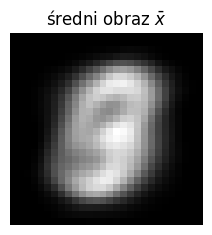

In [38]:
X_sub = x_train_flat[:2000]                                   # podzbiór, żeby SVD liczyło się szybko
mu = X_sub.mean(axis=0)                                       # średni obraz
U, S, Vt = np.linalg.svd(X_sub - mu, full_matrices=False)     # SVD wycentrowanych danych
lam_svd = S ** 2 / (len(X_sub) - 1)                           # wartości własne macierzy kowariancji

pca_ref = PCA(n_components=5).fit(X_sub)
print("wartości własne (SVD):    ", lam_svd[:5].round(3))
print("wartości własne (sklearn):", pca_ref.explained_variance_.round(3))
print("|cos| kąta między kierunkami:", np.abs(np.sum(Vt[:5] * pca_ref.components_, axis=1)).round(4))

plt.figure(figsize=(2.5, 2.5)); plt.imshow(mu.reshape(28, 28), cmap="gray"); plt.axis("off")
plt.title("średni obraz $\\bar{x}$"); plt.show()

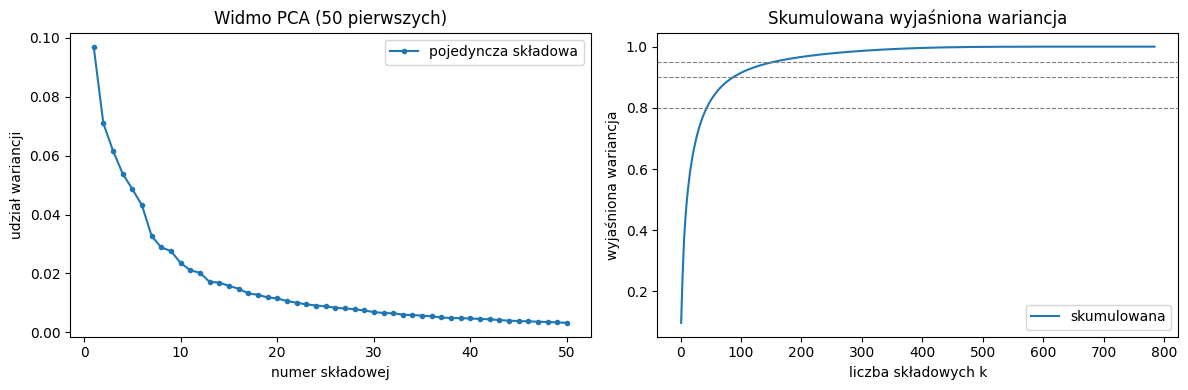

2 składowe wyjaśniają 16.8% wariancji


In [39]:
# PCA ze wszystkimi składowymi - potrzebujemy pełnego widma wartości własnych
pca_full = PCA(random_state=SEED).fit(x_train_flat)          # dopasowanie TYLKO na train
evr = pca_full.explained_variance_ratio_                       # udział wariancji każdej składowej
cum = np.cumsum(evr)                                           # skumulowana wyjaśniona wariancja

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, 51), evr[:50], "o-", ms=3, label="pojedyncza składowa")
ax[0].set_xlabel("numer składowej"); ax[0].set_ylabel("udział wariancji"); ax[0].set_title("Widmo PCA (50 pierwszych)")
ax[0].legend()
ax[1].plot(np.arange(1, len(cum) + 1), cum, label="skumulowana")
for prog in (0.8, 0.9, 0.95):
    ax[1].axhline(prog, ls="--", lw=0.8, color="gray")
ax[1].set_xlabel("liczba składowych k"); ax[1].set_ylabel("wyjaśniona wariancja"); ax[1].set_title("Skumulowana wyjaśniona wariancja")
ax[1].legend(); plt.tight_layout(); plt.show()
print(f"2 składowe wyjaśniają {cum[1]:.1%} wariancji")

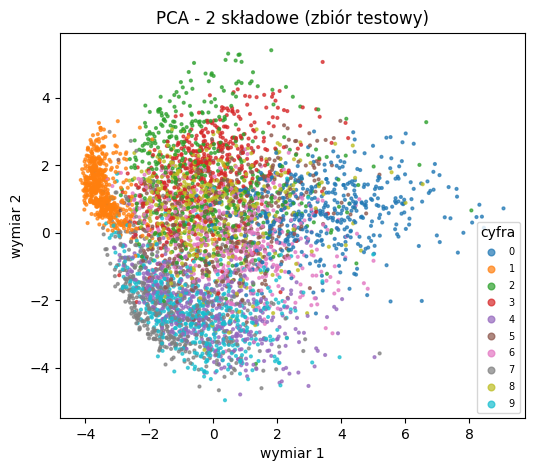

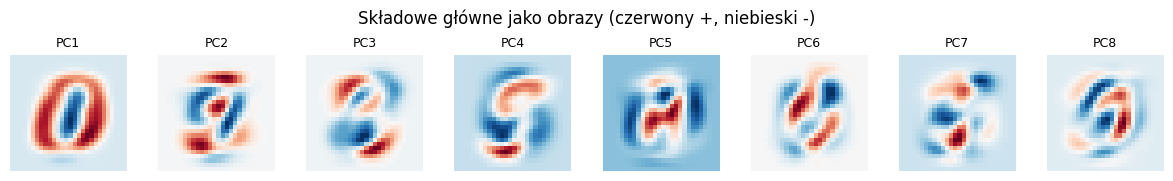

In [40]:
# Rzut na 2 pierwsze składowe i wizualizacja (dla N_VIZ punktów testowych)
pca2 = PCA(n_components=2, random_state=SEED).fit(x_train_flat)
z_pca2 = pca2.transform(x_test_flat[:N_VIZ])
scatter_2d(z_pca2, y_test[:N_VIZ], "PCA - 2 składowe (zbiór testowy)")
plt.show()

# Pierwsze składowe główne same są "obrazami" 28x28 - można je obejrzeć
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for i, ax in enumerate(axes):
    ax.imshow(pca_full.components_[i].reshape(28, 28), cmap="RdBu_r")
    ax.set_title(f"PC{i+1}", fontsize=9); ax.axis("off")
fig.suptitle("Składowe główne jako obrazy (czerwony +, niebieski -)")
plt.tight_layout(); plt.show()

**Co obserwować:** cyfra 1 i cyfra 0 zwykle leżą na przeciwnych końcach osi PC1 (PC1 mierzy z grubsza "ile tuszu jest na obrzeżach vs w środku"). Pozostałe cyfry mocno się nakładają - dwie liniowe osie to za mało.

### Zadanie 2.1 - ile składowych potrzeba?

1. Wyznacz najmniejsze $k$, dla którego skumulowana wyjaśniona wariancja przekracza 80%, 90% i 95%. Zapisz je w słowniku `k_progi` (klucz: próg, wartość: $k$).
2. Dla $k \in \{2, 10, 50, 150\}$ dopasuj PCA, zrekonstruuj pierwsze 10 obrazów testowych (`transform` + `inverse_transform`) i policz średni MSE na całym zbiorze testowym. Wyniki zapisz w słowniku `mse_pca_k`.
3. Narysuj rekonstrukcje (funkcja `pokaz_rekonstrukcje`).

**Kryteria sukcesu:** dla pełnego MNIST $k_{90\%}$ wynosi ok. 87, $k_{95\%}$ ok. 154; przy $k=50$ cyfry są już dobrze czytelne.

**Wskazówki:** `np.argmax(cum >= prog) + 1`; `pca.inverse_transform(pca.transform(X))`.

k dla progów wariancji: {0.8: 44, 0.9: 87, 0.95: 154}
MSE rekonstrukcji PCA: {2: 0.0557, 10: 0.0341, 50: 0.0115, 150: 0.0034}


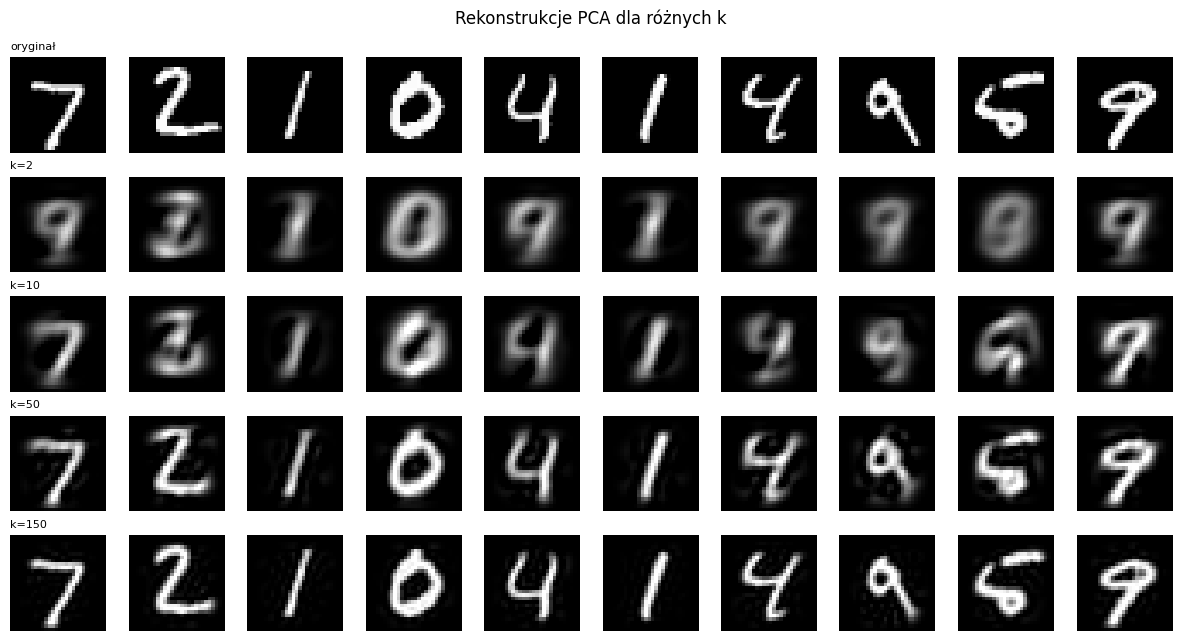

In [41]:
k_progi = {}
mse_pca_k = {}
rek_lista = []
for prog in [.8,.9,.95]:
    k_progi[prog]=int(np.searchsorted(cum,prog)+1)
for k in [2,10,50,150]:
    pca_k=PCA(n_components=k,random_state=SEED).fit(x_train_flat)
    rek=pca_k.inverse_transform(pca_k.transform(x_test_flat))
    mse_pca_k[k]=float(mse_per_sample(x_test_flat,rek).mean())
    rek_lista.append(np.clip(rek[:10],0,1))
print("k dla progów wariancji:", k_progi)
print("MSE rekonstrukcji PCA:", {k: round(v, 4) for k, v in mse_pca_k.items()})
if rek_lista:
    pokaz_rekonstrukcje(x_test_flat[:10], rek_lista, tytuly=("oryginał", "k=2", "k=10", "k=50", "k=150"),
                        suptitle="Rekonstrukcje PCA dla różnych k")

## 3. TruncatedSVD i LDA

**TruncatedSVD** rozkłada macierz danych $X \approx U_k \Sigma_k V_k^\top$ **bez centrowania**. Dzięki temu działa na macierzach rzadkich (np. tekst w reprezentacji TF-IDF), których centrowanie zniszczyłoby rzadkość. Dla danych wycentrowanych SVD i PCA dają te same kierunki. Na MNIST (niewycentrowanym) pierwsza składowa SVD opisuje głównie "średni obraz" - jasność.

**LDA (Linear Discriminant Analysis)** jest **metodą nadzorowaną** - korzysta z etykiet! Szuka kierunków maksymalizujących stosunek rozproszenia międzyklasowego $S_B$ do wewnątrzklasowego $S_W$:
$$J(\mathbf{w}) = \frac{\mathbf{w}^\top S_B \mathbf{w}}{\mathbf{w}^\top S_W \mathbf{w}}.$$
Ponieważ $S_B$ jest sumą $C$ macierzy rzędu 1 ograniczonych średnią globalną, ma rząd co najwyżej $C-1$. Dlatego **LDA daje maksymalnie $C-1$ wymiarów** - dla 10 cyfr to 9.

Ważne rozróżnienie (pytanie kolokwialne!): PCA i SVD maksymalizują wariancję / jakość rekonstrukcji bez etykiet; LDA maksymalizuje separowalność klas, ale wymaga etykiet i nie służy do rekonstrukcji.

Wyjaśniona wariancja przez 2 składowe SVD: [0.058 0.082]


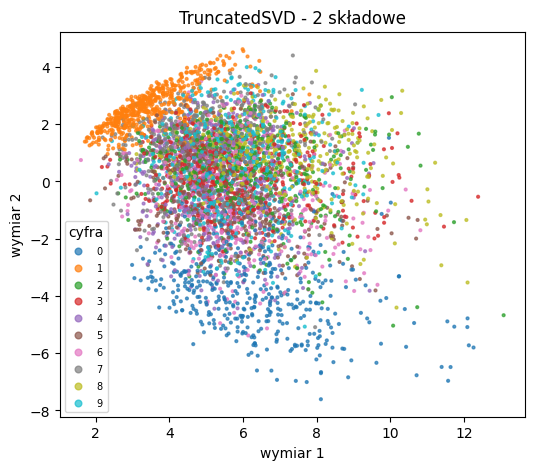

In [42]:
# TruncatedSVD na 2 składowe (bez centrowania danych)
svd2 = TruncatedSVD(n_components=2, random_state=SEED).fit(x_train_flat)
z_svd2 = svd2.transform(x_test_flat[:N_VIZ])
print("Wyjaśniona wariancja przez 2 składowe SVD:", svd2.explained_variance_ratio_.round(3))
scatter_2d(z_svd2, y_test[:N_VIZ], "TruncatedSVD - 2 składowe")
plt.show()

### Zadanie 3.1 - LDA i porównanie trzech metod

1. Dopasuj `LinearDiscriminantAnalysis(n_components=2)` na `(x_train_flat, y_train)` i przekształć `x_test_flat[:N_VIZ]` do zmiennej `z_lda2`.
2. Spróbuj utworzyć LDA z `n_components=10` - co się stanie? Obsłuż wyjątek `try/except` i wypisz komunikat.
3. Dopasuj LDA z maksymalną dopuszczalną liczbą składowych i wypisz sumę `explained_variance_ratio_`.
4. Narysuj obok siebie trzy wykresy 2D: PCA, SVD, LDA (użyj `scatter_2d(..., ax=...)`).

**Kryteria sukcesu:** na wykresie LDA klasy są wyraźnie lepiej rozdzielone niż w PCA. Umiesz wyjaśnić, dlaczego to porównanie jest "nieuczciwe" względem PCA.

**Wskazówki:** LDA na surowych pikselach może zgłosić ostrzeżenie o współliniowości (stałe, czarne piksele) - to normalne. Parametr `solver="svd"` (domyślny) radzi sobie z tym dobrze.

LDA ogranicza liczbę wymiarów do liczby klas minus 1: n_components cannot be larger than min(n_features, n_classes - 1).
Suma explained_variance_ratio (9D): 0.99999994


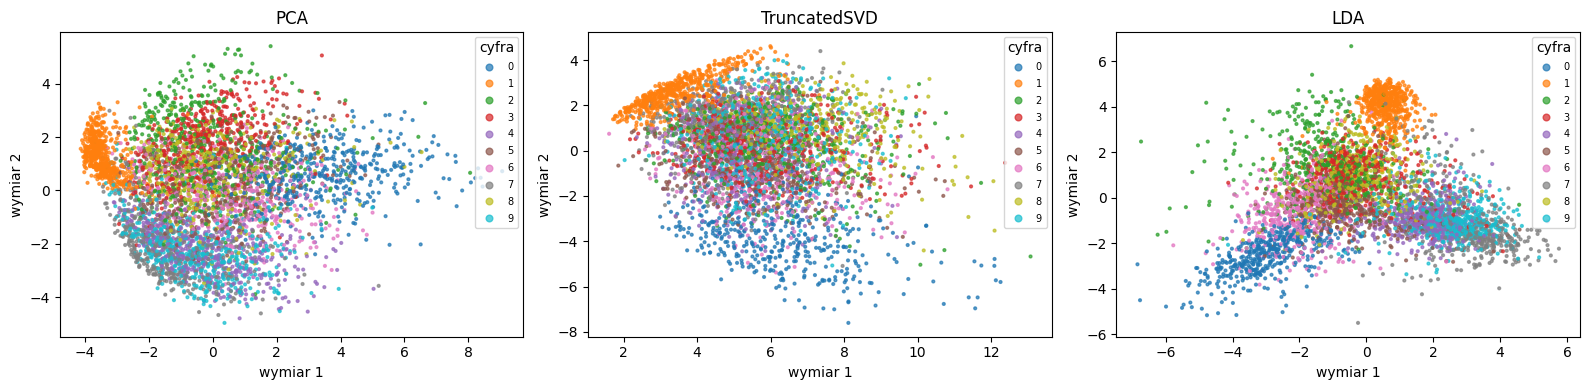

In [43]:
lda2=LinearDiscriminantAnalysis(n_components=2).fit(x_train_flat,y_train)
z_lda2=lda2.transform(x_test_flat[:N_VIZ])
try:
    LinearDiscriminantAnalysis(n_components=10).fit(x_train_flat,y_train).transform(x_test_flat[:10])
except ValueError as e:
    print("LDA ogranicza liczbę wymiarów do liczby klas minus 1:",e)
lda9=LinearDiscriminantAnalysis(n_components=9).fit(x_train_flat,y_train)
print("Suma explained_variance_ratio (9D):",lda9.explained_variance_ratio_.sum())
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,z,title in zip(axes,[z_pca2,z_svd2,z_lda2],["PCA","TruncatedSVD","LDA"]):
    scatter_2d(z,y_test[:N_VIZ],title,ax=ax)
plt.tight_layout();plt.show()

## 4. Autoenkoder gęsty

**Autoenkoder (W5)** to sieć uczona odtwarzać swoje wejście: $\hat{\mathbf{x}} = g_\theta(f_\phi(\mathbf{x}))$, gdzie
- **enkoder** $f_\phi: \mathbb{R}^{784} \to \mathbb{R}^{d}$ kompresuje obraz do wektora ukrytego (latentnego) $\mathbf{z}$,
- **dekoder** $g_\theta: \mathbb{R}^{d} \to \mathbb{R}^{784}$ odtwarza obraz,
- **wąskie gardło** $d \ll 784$ zmusza sieć do zapamiętania tylko tego, co najważniejsze.

Uczymy minimalizując stratę rekonstrukcji, np. $\mathcal{L} = \frac{1}{N}\sum_i \lVert \mathbf{x}_i - \hat{\mathbf{x}}_i\rVert^2$ (MSE) albo binarną entropię krzyżową na pikselach (BCE), gdy piksele są w $[0,1]$. **Etykietą jest samo wejście** - stąd `model.fit(x, x)`.

Różnica względem PCA: enkoder i dekoder są **nieliniowe** (ReLU), więc AE może "rozwinąć" zakrzywioną rozmaitość, której PCA nie potrafi spłaszczyć bez straty.

Budujemy enkoder i dekoder jako **osobne modele** Functional API, a autoenkoder jako ich złożenie. Dzięki temu po treningu możemy użyć samego enkodera (do wizualizacji, klasteryzacji) albo samego dekodera (do generowania z $\mathbf{z}$).

In [44]:
def zbuduj_ae_gesty(latent_dim, ukryte=(512, 256), aktywacja_latentu=None, nazwa="ae"):
    # Enkoder: 784 -> 512 -> 256 -> latent_dim
    wej = keras.Input(shape=(784,), name="obraz")
    h = wej
    for n in ukryte:
        h = layers.Dense(n, activation="relu")(h)
    z = layers.Dense(latent_dim, activation=aktywacja_latentu, name="z")(h)   # liniowy latent (domyślnie)
    enkoder = keras.Model(wej, z, name=f"{nazwa}_enkoder")

    # Dekoder: lustrzane odbicie enkodera, latent_dim -> 256 -> 512 -> 784
    wej_z = keras.Input(shape=(latent_dim,), name="z_wej")
    h = wej_z
    for n in reversed(ukryte):
        h = layers.Dense(n, activation="relu")(h)
    wyj = layers.Dense(784, activation="sigmoid", name="rekonstrukcja")(h)    # sigmoid -> piksele w [0, 1]
    dekoder = keras.Model(wej_z, wyj, name=f"{nazwa}_dekoder")

    # Autoenkoder = dekoder(enkoder(x))
    ae = keras.Model(wej, dekoder(enkoder(wej)), name=nazwa)
    ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["mse"])
    return ae, enkoder, dekoder

ae2, enc2, dec2 = zbuduj_ae_gesty(2, nazwa="ae2")
enc2.summary()
dec2.summary()

Model: "ae2_enkoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ obraz (InputLayer)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ z (Dense)                       │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,762 (2.04 MB)

 Trainable params: 533,762 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

Model: "ae2_dekoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ z_wej (InputLayer)              │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rekonstrukcja (Dense)           │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 534,544 (2.04 MB)

 Trainable params: 534,544 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

Uwaga do straty: używamy **BCE** dla pikseli w $[0,1]$ - działa jak "miękka" klasyfikacja każdego piksela (tło/tusz) i zwykle daje ostrzejsze rekonstrukcje niż MSE. Metrykę MSE zostawiamy, żeby porównywać się z PCA (które minimalizuje MSE).

Callback `EarlyStopping` z `restore_best_weights=True` chroni nas przed przeuczeniem i oszczędza czas. Jako walidację bierzemy 10% zbioru treningowego (`validation_split`), zbiór testowy zostaje do końcowej oceny.

Epoch 1/20
211/211 - 7s - 34ms/step - loss: 0.2558 - mse: 0.0650 - val_loss: 0.2183 - val_mse: 0.0529
Epoch 2/20
211/211 - 5s - 26ms/step - loss: 0.2093 - mse: 0.0502 - val_loss: 0.1987 - val_mse: 0.0464
Epoch 3/20
211/211 - 1s - 5ms/step - loss: 0.1961 - mse: 0.0457 - val_loss: 0.1901 - val_mse: 0.0434
Epoch 4/20
211/211 - 1s - 5ms/step - loss: 0.1889 - mse: 0.0432 - val_loss: 0.1847 - val_mse: 0.0415
Epoch 5/20
211/211 - 1s - 5ms/step - loss: 0.1847 - mse: 0.0417 - val_loss: 0.1820 - val_mse: 0.0406
Epoch 6/20
211/211 - 1s - 5ms/step - loss: 0.1819 - mse: 0.0407 - val_loss: 0.1801 - val_mse: 0.0399
Epoch 7/20
211/211 - 1s - 5ms/step - loss: 0.1801 - mse: 0.0401 - val_loss: 0.1785 - val_mse: 0.0393
Epoch 8/20
211/211 - 1s - 5ms/step - loss: 0.1786 - mse: 0.0395 - val_loss: 0.1777 - val_mse: 0.0391
Epoch 9/20
211/211 - 1s - 5ms/step - loss: 0.1773 - mse: 0.0391 - val_loss: 0.1765 - val_mse: 0.0386
Epoch 10/20
211/211 - 1s - 5ms/step - loss: 0.1762 - mse: 0.0387 - val_loss: 0.1758 - val

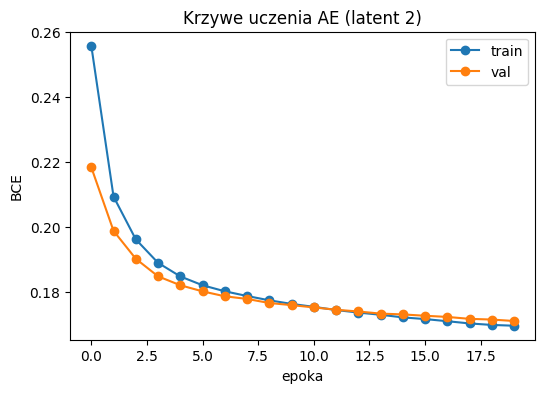

In [45]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]

t0 = time.time()
hist2 = ae2.fit(x_train_flat, x_train_flat,          # wejście = cel!
                epochs=EPOKI, batch_size=BATCH, validation_split=0.1,
                callbacks=callbacks, verbose=2)
print(f"Czas treningu: {time.time() - t0:.1f} s")

plt.figure(figsize=(6, 4))
plt.plot(hist2.history["loss"], "o-", label="train")
plt.plot(hist2.history["val_loss"], "o-", label="val")
plt.xlabel("epoka"); plt.ylabel("BCE"); plt.title("Krzywe uczenia AE (latent 2)"); plt.legend(); plt.show()

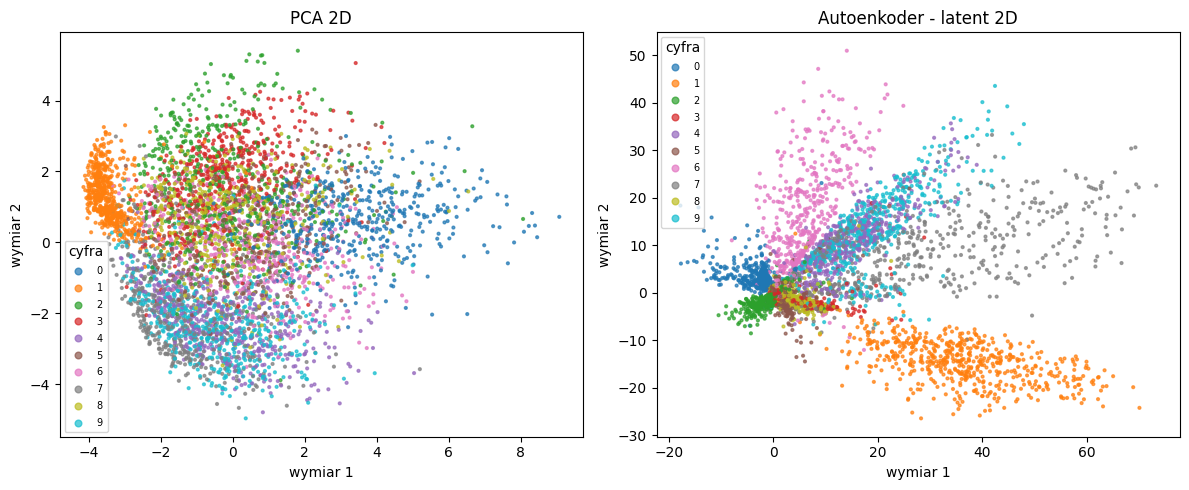

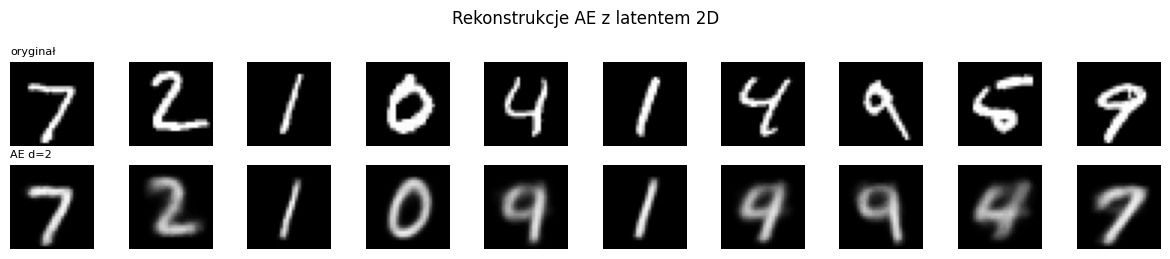

In [46]:
# Przestrzeń latentna 2D: każdy obraz testowy -> punkt (z1, z2)
z_ae2 = enc2.predict(x_test_flat[:N_VIZ], verbose=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
scatter_2d(z_pca2, y_test[:N_VIZ], "PCA 2D", ax=axes[0])
scatter_2d(z_ae2, y_test[:N_VIZ], "Autoenkoder - latent 2D", ax=axes[1])
plt.tight_layout(); plt.show()

# Rekonstrukcje z zaledwie 2 liczb
rek2 = ae2.predict(x_test_flat[:10], verbose=0)
pokaz_rekonstrukcje(x_test_flat[:10], rek2, tytuly=("oryginał", "AE d=2"), suptitle="Rekonstrukcje AE z latentem 2D")

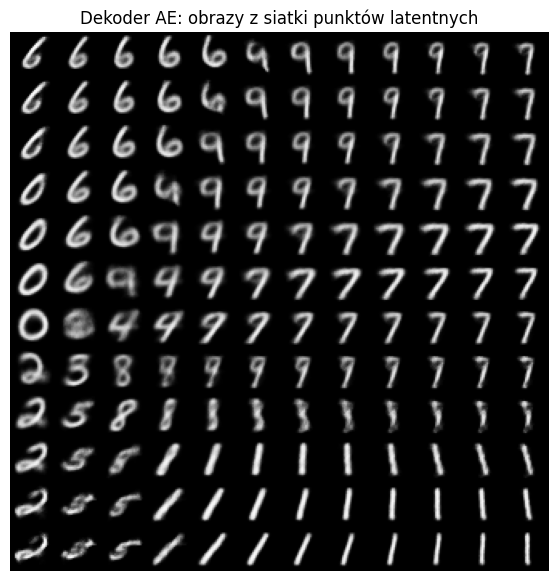

In [47]:
# Dekoder jako "generator": przechodzimy po siatce punktów w przestrzeni latentnej
n = 12
z1 = np.linspace(np.percentile(z_ae2[:, 0], 5), np.percentile(z_ae2[:, 0], 95), n)
z2 = np.linspace(np.percentile(z_ae2[:, 1], 5), np.percentile(z_ae2[:, 1], 95), n)
siatka = np.array([[a, b] for b in z2[::-1] for a in z1], dtype="float32")   # n*n punktów
obrazy = dec2.predict(siatka, verbose=0).reshape(n, n, 28, 28)
plansza = obrazy.transpose(0, 2, 1, 3).reshape(n * 28, n * 28)               # sklejamy w jeden obraz
plt.figure(figsize=(7, 7)); plt.imshow(plansza, cmap="gray"); plt.axis("off")
plt.title("Dekoder AE: obrazy z siatki punktów latentnych"); plt.show()

**Typowe błędy przy autoenkoderach:**
- `fit(x, y)` z etykietami zamiast `fit(x, x)`,
- brak skalowania do $[0,1]$ przy wyjściu `sigmoid` i stracie BCE (strata może wyjść ujemna),
- `relu` na wyjściu dekodera - nieograniczone wartości pikseli; `relu` na warstwie latentu przy małym $d$ - "martwe" wymiary (zawsze 0),
- porównywanie AE i PCA przy różnych $d$ albo na różnych zbiorach.

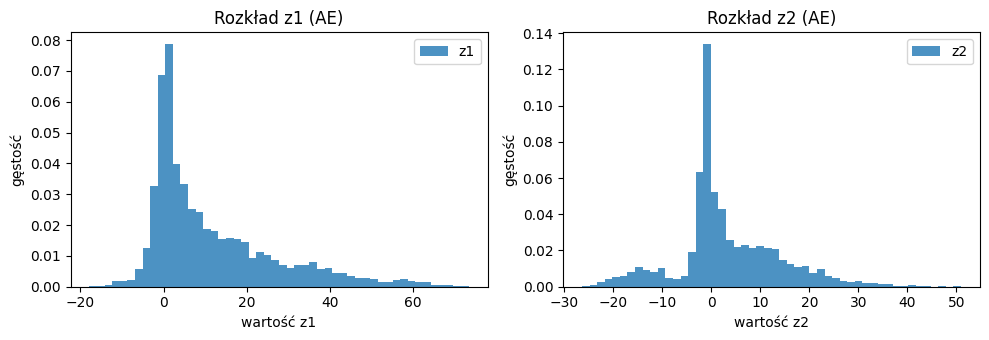

średnia: [11.49  3.13] odch. std.: [15.24 10.63]


In [48]:
# Rozkład współrzędnych latentnych AE 2D - porównaj z rozkładem normalnym N(0, 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for j in range(2):
    ax[j].hist(z_ae2[:, j], bins=50, alpha=0.8, density=True, label=f"z{j+1}")
    ax[j].set_xlabel(f"wartość z{j+1}"); ax[j].set_ylabel("gęstość"); ax[j].set_title(f"Rozkład z{j+1} (AE)")
    ax[j].legend()
plt.tight_layout(); plt.show()
print("średnia:", z_ae2.mean(0).round(2), "odch. std.:", z_ae2.std(0).round(2))

**Co obserwować:** w przestrzeni latentnej AE klasy tworzą wyraźniejsze, "promieniste" skupiska niż w PCA, mimo że AE nie widział etykiet. Na siatce dekodera widać płynne przejścia między cyframi, ale też obszary "pomiędzy" dające nieczytelne kształty - przestrzeń latentna zwykłego AE **nie jest regularna** (dziury, nierówna gęstość). Ten problem rozwiązuje VAE na Lab 7.

### Zadanie 4.1 - autoenkoder z latentem 32 vs PCA 32

1. Zbuduj i wytrenuj autoenkoder `ae32` z latentem 32 (funkcja `zbuduj_ae_gesty`), z tymi samymi callbackami i liczbą epok.
2. Policz średni MSE rekonstrukcji na zbiorze testowym dla `ae32` (`mse_ae32`) oraz dla PCA z 32 składowymi (`mse_pca32`).
3. Pokaż rekonstrukcje 10 obrazów: oryginał / PCA 32 / AE 32.

**Kryteria sukcesu:** `mse_ae32` wyraźnie mniejszy od `mse_pca32` (w pełnym trybie ok. 2-3 razy).

**Wskazówki:** `ae32.predict(...)`, `PCA(32).fit(...)`; pamiętaj o przycięciu rekonstrukcji PCA do $[0, 1]$ tylko przy rysowaniu, nie przy liczeniu MSE (dla uczciwości).

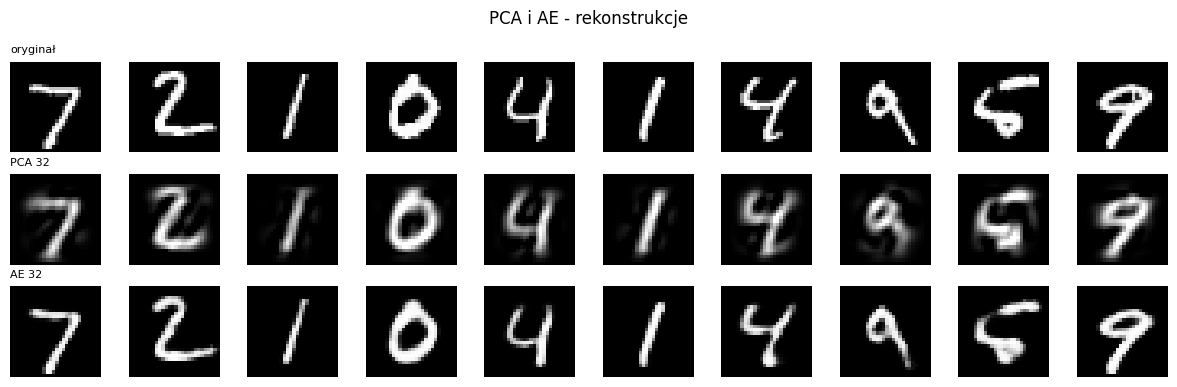

MSE PCA(32) = 0.016828233376145363, MSE AE(32) = 0.005452360492199659


In [49]:
ae32,enc32,dec32=zbuduj_ae_gesty(32,nazwa="ae32")
hist32=ae32.fit(x_train_flat,x_train_flat,epochs=EPOKI,batch_size=BATCH,
    validation_split=.1,callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)],verbose=0)
rek_ae32=ae32.predict(x_test_flat,verbose=0)
pca32=PCA(n_components=32,random_state=SEED).fit(x_train_flat)
rek_pca32=pca32.inverse_transform(pca32.transform(x_test_flat))
mse_ae32=float(mse_per_sample(x_test_flat,rek_ae32).mean())
mse_pca32=float(mse_per_sample(x_test_flat,rek_pca32).mean())
pokaz_rekonstrukcje(x_test_flat[:10],[np.clip(rek_pca32[:10],0,1),rek_ae32[:10]],
   tytuly=("oryginał","PCA 32","AE 32"),suptitle="PCA i AE - rekonstrukcje")
print(f"MSE PCA(32) = {mse_pca32}, MSE AE(32) = {mse_ae32}")

## 5. Błąd rekonstrukcji w funkcji wymiaru: AE vs PCA

Stawiamy **hipotezę (UGŁ_U01):** *nieliniowy autoenkoder ma mniejszy błąd rekonstrukcji niż PCA przy każdym wymiarze $d$, a przewaga jest największa dla małych $d$.* Uzasadnienie: przy dużym $d$ obie metody mają "dość miejsca", przy małym liczy się umiejętność opisania zakrzywionej rozmaitości.

Weryfikacja wymaga pętli po wymiarach. Każdy AE trenujemy krócej (`EPOKI_KROTKO`) - interesuje nas trend, nie rekord.

### Zadanie 5.1 - krzywa MSE(d)

1. Dla każdego `d` z listy `WYMIARY` wytrenuj AE gęsty i PCA, policz MSE rekonstrukcji na teście.
2. Zapisz wyniki w liście słowników `wyniki_d` z kluczami `d`, `mse_pca`, `mse_ae` i zamień na `pd.DataFrame`.
3. Narysuj obie krzywe (oś $y$ w skali logarytmicznej) i skomentuj, czy hipoteza się potwierdziła.

**Kryteria sukcesu:** wykres z dwiema krzywymi, legendą i opisanymi osiami; krzywa AE poniżej PCA.

**Wskazówki:** w pętli używaj `verbose=0`; po każdym modelu możesz wywołać `keras.backend.clear_session()`, żeby nie zapychać pamięci.

,d,mse_pca,mse_ae
0,2,0.055669,0.038917
1,4,0.047904,0.028336
2,8,0.037441,0.016475
3,16,0.026860,0.009897
4,32,0.016828,0.006130
5,64,0.009047,0.004737


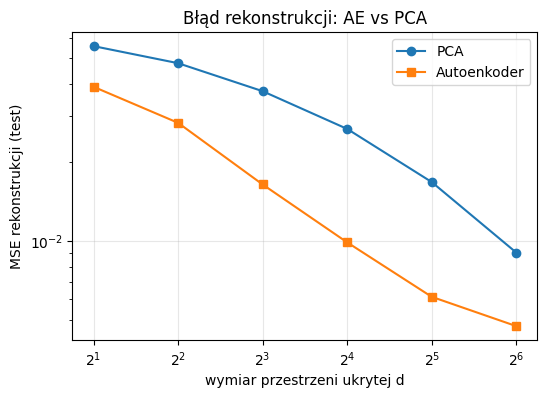

In [50]:
WYMIARY = [2, 8, 32] if SZYBKI_TRYB else [2, 4, 8, 16, 32, 64]
wyniki_d = []
for wymiar in WYMIARY:
    pca_d=PCA(n_components=wymiar,random_state=SEED).fit(x_train_flat)
    pred_pca=pca_d.inverse_transform(pca_d.transform(x_test_flat))
    ae_d,_,_=zbuduj_ae_gesty(wymiar,nazwa=f"ae_d{wymiar}")
    ae_d.fit(x_train_flat,x_train_flat,epochs=EPOKI_KROTKO,batch_size=BATCH,verbose=0)
    pred_ae=ae_d.predict(x_test_flat,verbose=0)
    wyniki_d.append({"d":wymiar,"mse_pca":mse_per_sample(x_test_flat,pred_pca).mean(),
                      "mse_ae":mse_per_sample(x_test_flat,pred_ae).mean()})
df_d = pd.DataFrame(wyniki_d)
display(df_d)
if len(df_d):
    plt.figure(figsize=(6, 4))
    plt.plot(df_d["d"], df_d["mse_pca"], "o-", label="PCA")
    plt.plot(df_d["d"], df_d["mse_ae"], "s-", label="Autoenkoder")
    plt.xscale("log", base=2); plt.yscale("log")
    plt.xlabel("wymiar przestrzeni ukrytej d"); plt.ylabel("MSE rekonstrukcji (test)")
    plt.title("Błąd rekonstrukcji: AE vs PCA"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 6. Liniowy autoenkoder ≈ PCA

Ważny wynik teoretyczny (Baldi i Hornik, 1989): autoenkoder **bez nieliniowości**, z jedną warstwą ukrytą o $k$ neuronach i stratą MSE, w optimum rozpina **tę samą podprzestrzeń**, co $k$ pierwszych składowych PCA. Nie musi jednak znaleźć tych samych wektorów - wagi mogą być dowolną (nieortogonalną) bazą tej podprzestrzeni. Dlatego porównujemy **podprzestrzenie**, a nie pojedyncze wektory.

Narzędzie: **kąty główne** (*principal angles*) między podprzestrzeniami, `scipy.linalg.subspace_angles(A, B)`. Kąty bliskie 0° oznaczają, że podprzestrzenie się pokrywają.

Wniosek dydaktyczny: autoenkoder jest **uogólnieniem PCA** - to nieliniowość daje mu przewagę z sekcji 5.

### Zadanie 6.1 - weryfikacja "liniowy AE ≈ PCA"

1. Zbuduj liniowy AE z $k = 16$: `Input(784) -> Dense(16, bez aktywacji) -> Dense(784, bez aktywacji)`, strata MSE, optymalizator Adam (lr = 1e-3). Wytrenuj na `x_train_flat`.
2. Policz MSE na teście i porównaj z PCA(16) (`mse_lin_ae`, `mse_pca16`).
3. Wyznacz kąty główne między podprzestrzenią rozpiętą przez wiersze macierzy wag dekodera (kształt `16 x 784`) a `pca16.components_`. Wypisz największy kąt w stopniach.

**Kryteria sukcesu:** MSE liniowego AE bliskie PCA (nieco wyższe, bo optymalizacja gradientowa nie dochodzi do optimum w kilku epokach); kąty maleją wraz z liczbą epok.

**Wskazówki:** wagi warstwy: `model.layers[-1].get_weights()[0]`; `np.degrees(subspace_angles(W.T, pca16.components_.T))`.

In [51]:
from scipy.linalg import subspace_angles
EPOKI_LIN = 2 if SZYBKI_TRYB else 30
we_lin=keras.Input(shape=(784,))
z_lin=layers.Dense(16,activation=None,name="latent_liniowy")(we_lin)
wy_lin=layers.Dense(784,activation=None,name="dekoder_liniowy")(z_lin)
ae_lin=keras.Model(we_lin,wy_lin)
ae_lin.compile(optimizer=keras.optimizers.Adam(1e-3),loss="mse")
ae_lin.fit(x_train_flat,x_train_flat,epochs=EPOKI_LIN,batch_size=BATCH,verbose=0)
rek_lin=ae_lin.predict(x_test_flat,verbose=0)
mse_lin_ae=float(mse_per_sample(x_test_flat,rek_lin).mean())
pca16=PCA(n_components=16,random_state=SEED).fit(x_train_flat)
mse_pca16=float(mse_per_sample(x_test_flat,pca16.inverse_transform(pca16.transform(x_test_flat))).mean())
W_dek=ae_lin.get_layer("dekoder_liniowy").get_weights()[0]
katy=np.degrees(subspace_angles(W_dek.T,pca16.components_.T))
print(f"MSE liniowy AE = {mse_lin_ae}, MSE PCA(16) = {mse_pca16}")
if katy is not None:
    print("Kąty główne [°] (od największego):", np.round(np.sort(katy)[::-1], 1))

MSE liniowy AE = 0.026911403983831406, MSE PCA(16) = 0.026860311627388
Kąty główne [°] (od największego): [2.6 2.6 2.3 2.1 2.  1.9 1.8 1.8 1.7 1.6 1.6 1.6 1.4 1.3 1.1 0.8]


## 7. Klasteryzacja w różnych przestrzeniach cech

**Pytanie badawcze:** czy k-means znajdzie "cyfry" bez etykiet? I w której reprezentacji - surowe piksele, PCA czy latent AE - zrobi to najlepiej? To prosta wersja **deep clustering** z W5 (DEC idzie dalej - wspólnie dostraja enkoder i centra skupień).

**k-means** minimalizuje sumę kwadratów odległości punktów od centrów skupień $\sum_i \lVert \mathbf{x}_i - \boldsymbol{\mu}_{c(i)} \rVert^2$. Zakłada skupienia "kuliste" w metryce euklidesowej - dlatego wybór przestrzeni ma ogromne znaczenie.

**Metryki (W5):**
- **ARI** (Adjusted Rand Index) - zgodność podziału z etykietami prawdziwymi, skorygowana o przypadek: 0 = losowo, 1 = idealnie. Niezależna od numeracji skupień.
- **NMI** (Normalized Mutual Information) - wzajemna informacja między podziałami znormalizowana do $[0, 1]$.
- **Silhouette** - **wewnętrzna** miara (bez etykiet): $s = \frac{b - a}{\max(a, b)}$, gdzie $a$ to średnia odległość do punktów swojego skupienia, $b$ do najbliższego obcego. Zakres $[-1, 1]$. Uwaga: silhouette liczony w różnych przestrzeniach **nie jest bezpośrednio porównywalny** (inna skala i wymiar).

ARI i NMI wymagają etykiet - w prawdziwym problemie nienadzorowanym ich nie mamy; tu używamy ich, by ocenić metodę.

In [52]:
def ocen_klasteryzacje(X, y, nazwa, k=10):
    # k-means + trzy metryki; silhouette na podpróbce (koszt O(N^2))
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    etyk = km.labels_
    return {"przestrzeń": nazwa, "wymiar": X.shape[1],
            "ARI": adjusted_rand_score(y, etyk),
            "NMI": normalized_mutual_info_score(y, etyk),
            "silhouette": silhouette_score(X, etyk, sample_size=min(2000, len(X)), random_state=SEED)}

# Przykład: k-means na surowych pikselach
Xk, yk = x_test_flat[:N_VIZ], y_test[:N_VIZ]
print(ocen_klasteryzacje(Xk, yk, "piksele"))

{'przestrzeń': 'piksele', 'wymiar': 784, 'ARI': 0.41425292740069103, 'NMI': np.float64(0.5118248030824459), 'silhouette': np.float32(0.06935675)}


### Zadanie 7.1 - tabela porównawcza klasteryzacji

Zbuduj tabelę `df_klast` (DataFrame) z wynikami `ocen_klasteryzacje` dla przestrzeni:
1. surowe piksele (784),
2. PCA(32) (dopasowane na train, transformacja `Xk`),
3. latent AE 32 (`enc32` z Zadania 4.1),
4. latent AE 2 (`enc2`),
5. *(opcjonalnie)* PCA(2).

Wynik posortuj malejąco po ARI i narysuj wykres słupkowy ARI i NMI.

**Kryteria sukcesu:** latent AE daje wyższe ARI/NMI niż piksele (w pełnym trybie ARI ok. 0.5-0.7 dla AE vs ok. 0.35-0.4 dla pikseli).

**Wskazówki:** `pd.DataFrame(lista_słowników).sort_values("ARI", ascending=False)`; `df.plot.bar(x="przestrzeń", y=["ARI", "NMI"])`.

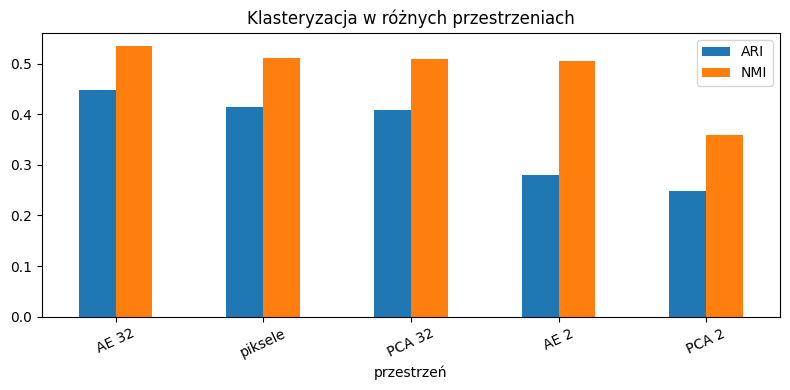

,przestrzeń,wymiar,ARI,NMI,silhouette
2,AE 32,32,0.447,0.534,0.121
0,piksele,784,0.414,0.512,0.069
1,PCA 32,32,0.408,0.508,0.111
3,AE 2,2,0.279,0.505,0.434
4,PCA 2,2,0.249,0.360,0.362


In [53]:
klast_wyn=[ocen_klasteryzacje(Xk,yk,"piksele")]
klast_wyn.append(ocen_klasteryzacje(pca32.transform(Xk),yk,"PCA 32"))
klast_wyn.append(ocen_klasteryzacje(enc32.predict(Xk,verbose=0),yk,"AE 32"))
klast_wyn.append(ocen_klasteryzacje(enc2.predict(Xk,verbose=0),yk,"AE 2"))
klast_wyn.append(ocen_klasteryzacje(pca2.transform(Xk),yk,"PCA 2"))
df_klast=pd.DataFrame(klast_wyn).sort_values("ARI",ascending=False)
df_klast.plot.bar(x="przestrzeń",y=["ARI","NMI"],figsize=(8,4),rot=25)
plt.title("Klasteryzacja w różnych przestrzeniach");plt.tight_layout();plt.show()
display(df_klast.round(3) if len(df_klast) else df_klast)

### Które cyfry k-means myli? Macierz kontyngencji

Numery skupień z k-means są **dowolne** (skupienie 3 nie musi odpowiadać cyfrze 3). Dlatego zamiast accuracy oglądamy tablicę kontyngencji: wiersze - prawdziwa cyfra, kolumny - numer skupienia. Dobre skupienie ma jedną dominującą cyfrę w kolumnie.

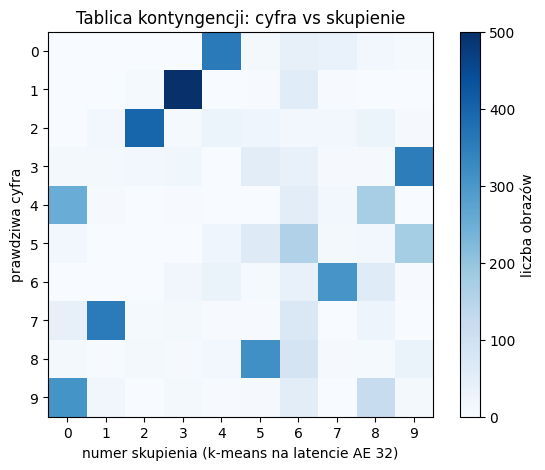

purity = 0.644


In [54]:
km_ae = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit(enc32.predict(Xk, verbose=0))
tab = pd.crosstab(pd.Series(yk, name="cyfra"), pd.Series(km_ae.labels_, name="skupienie"))
plt.figure(figsize=(7, 5))
plt.imshow(tab.values, cmap="Blues"); plt.colorbar(label="liczba obrazów")
plt.xticks(range(tab.shape[1]), tab.columns); plt.yticks(range(tab.shape[0]), tab.index)
plt.xlabel("numer skupienia (k-means na latencie AE 32)"); plt.ylabel("prawdziwa cyfra")
plt.title("Tablica kontyngencji: cyfra vs skupienie"); plt.show()
# Czystość (purity): odsetek obrazów należących do dominującej cyfry w swoim skupieniu
print(f"purity = {tab.max(axis=0).sum() / tab.values.sum():.3f}")

### Wizualizacja nieliniowa: t-SNE latentu

t-SNE (W5) to metoda **wyłącznie do wizualizacji**: zachowuje lokalne sąsiedztwa, ale odległości między odległymi skupieniami i ich rozmiary nie mają znaczenia. Nie stosujemy jej do transformacji nowych danych (brak `transform`) ani jako cech do klasyfikatora. Poniżej t-SNE na 32-wymiarowym latencie AE.

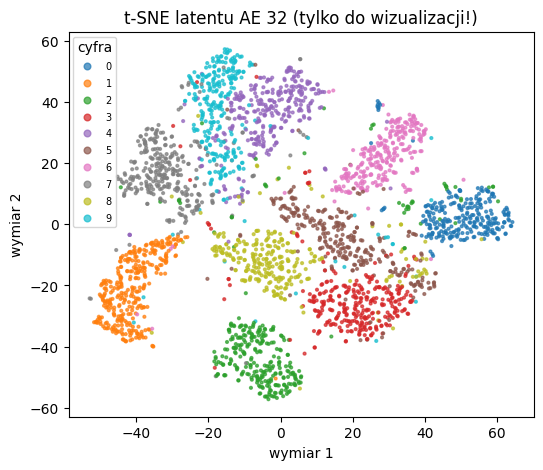

In [55]:
from sklearn.manifold import TSNE
n_tsne = min(1000 if SZYBKI_TRYB else 3000, len(Xk))
z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(
    enc32.predict(Xk[:n_tsne], verbose=0))
scatter_2d(z_tsne, yk[:n_tsne], "t-SNE latentu AE 32 (tylko do wizualizacji!)")
plt.show()

## 8. Autoenkoder odszumiający (Denoising AE)

Zamiast uczyć $\mathbf{x} \to \mathbf{x}$, uczymy **zaszumione wejście -> czysty cel**: $\tilde{\mathbf{x}} = \mathbf{x} + \sigma\boldsymbol{\epsilon}$, $\boldsymbol{\epsilon} \sim \mathcal{N}(0, I)$, strata $\mathcal{L}(\mathbf{x}, g(f(\tilde{\mathbf{x}})))$. Sieć nie może po prostu "przepisać" wejścia (nawet z dużym latentem), musi nauczyć się **struktury cyfr**, aby odróżnić ją od szumu. To jedna z najważniejszych idei uczenia reprezentacji - jest też fundamentem modeli dyfuzyjnych (W5), które uczą się odszumiania na wielu poziomach szumu.

Miara jakości: **PSNR** (Peak Signal-to-Noise Ratio) $= 10 \log_{10}\frac{1}{\text{MSE}}$ dla obrazów w $[0,1]$ - im wyższy, tym lepiej (w dB).

Typowy błąd: dodawanie szumu i trenowanie na `(x_noisy, x_noisy)` - wtedy sieć uczy się odtwarzać szum.

PSNR obrazu zaszumionego względem czystego: 9.37 dB


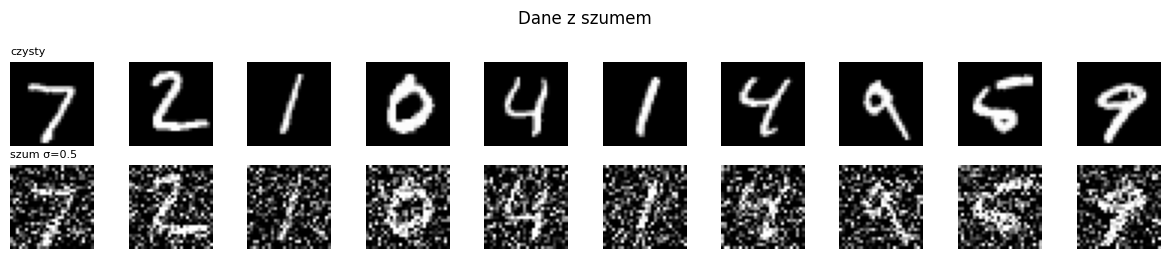

In [56]:
SIGMA = 0.5   # odchylenie standardowe szumu gaussowskiego
rng = np.random.default_rng(SEED)
x_train_noisy = np.clip(x_train_flat + SIGMA * rng.normal(size=x_train_flat.shape), 0, 1).astype("float32")
x_test_noisy = np.clip(x_test_flat + SIGMA * rng.normal(size=x_test_flat.shape), 0, 1).astype("float32")

def psnr(x, x_hat):
    # PSNR w dB dla obrazów w [0, 1], uśredniony po próbkach
    return float(np.mean(10 * np.log10(1.0 / np.maximum(mse_per_sample(x, x_hat), 1e-10))))

print(f"PSNR obrazu zaszumionego względem czystego: {psnr(x_test_flat, x_test_noisy):.2f} dB")
pokaz_rekonstrukcje(x_test_flat[:10], x_test_noisy[:10], tytuly=("czysty", f"szum σ={SIGMA}"), suptitle="Dane z szumem")

### Zadanie 8.1 - trening DAE i porównanie

1. Zbuduj AE gęsty z latentem 64 (`zbuduj_ae_gesty(64, nazwa="dae")`) i wytrenuj go na parach `(x_train_noisy, x_train_flat)`.
2. Odszum `x_test_noisy`. Policz PSNR dla: wejścia zaszumionego, wyjścia DAE oraz wyjścia **zwykłego** `ae32` z Zadania 4.1 podanego na zaszumione wejście.
3. Pokaż trzy wiersze: zaszumione / DAE / czyste.

**Kryteria sukcesu:** PSNR DAE wyższy o kilka dB niż PSNR wejścia i wyższy niż zwykłego AE.

**Wskazówki:** `validation_data=(x_test_noisy, x_test_flat)` pozwala śledzić jakość na teście w trakcie treningu (tu dopuszczalne do monitorowania, ale do wyboru hiperparametrów użylibyśmy osobnej walidacji).

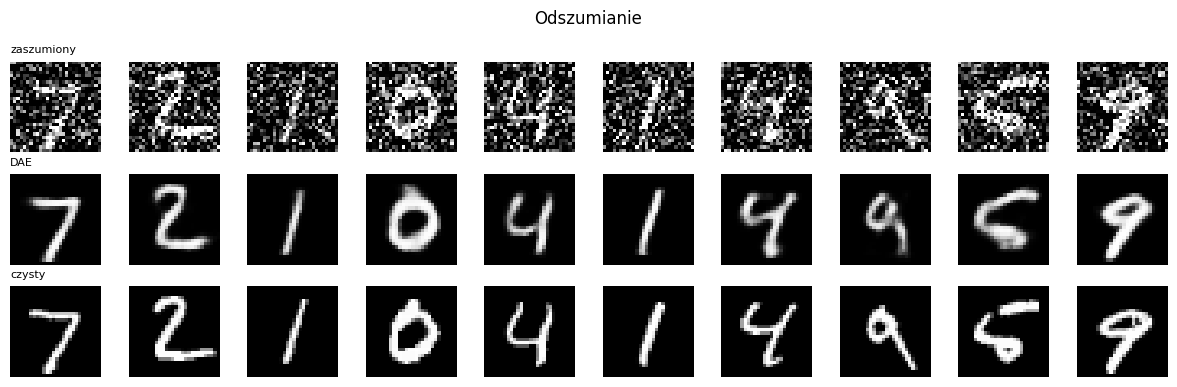

PSNR: wejście 9.37 dB | zwykły AE 11.239999771118164 | DAE 18.726743698120117


In [57]:
dae,enc_dae,dec_dae=zbuduj_ae_gesty(64,nazwa="dae")
dae.fit(x_train_noisy,x_train_flat,epochs=EPOKI,batch_size=BATCH,
        validation_split=.1,verbose=0)
rek_dae=dae.predict(x_test_noisy,verbose=0)
rek_ae_zwykly=ae32.predict(x_test_noisy,verbose=0)
psnr_dae=psnr(x_test_flat,rek_dae)
psnr_ae_zwykly=psnr(x_test_flat,rek_ae_zwykly)
pokaz_rekonstrukcje(x_test_noisy[:10],[rek_dae[:10],x_test_flat[:10]],
 tytuly=("zaszumiony","DAE","czysty"),suptitle="Odszumianie")
print(f"PSNR: wejście {psnr(x_test_flat, x_test_noisy):.2f} dB | zwykły AE {psnr_ae_zwykly} | DAE {psnr_dae}")

## 9. Autoenkoder konwolucyjny - "warstwy rozwijające"

AE gęsty traktuje obraz jak wektor i ignoruje sąsiedztwo pikseli. **AE konwolucyjny** w enkoderze używa `Conv2D` (+ stride lub pooling) do redukcji rozdzielczości, a w dekoderze **splotu transponowanego** `Conv2DTranspose` (lub `UpSampling2D` + `Conv2D`) do jej odtworzenia. To są "warstwy rozwijające/zwijające" z treści T2 programu (W2).

**Wymiar wyjścia** (padding `"same"`): `Conv2D` ze stride $s$: $H_{out} = \lceil H/s \rceil$; `Conv2DTranspose` ze stride $s$: $H_{out} = H \cdot s$. Ogólnie dla `padding="valid"`: $H_{out}^{conv} = \lfloor (H - k)/s \rfloor + 1$ i $H_{out}^{tr} = (H - 1)s + k$.

Splot transponowany to **operacja odwrotna co do kształtu** (nie co do wartości!) - można o nim myśleć jak o "rozsmarowaniu" każdego piksela wejścia filtrem na większą siatkę. Przy $k$ niepodzielnym przez $s$ powstają artefakty szachownicy (*checkerboard*) - alternatywą jest `UpSampling2D` + `Conv2D`.

Plan sieci: $28\times28\times1 \to 14\times14\times32 \to 7\times7\times64 \to$ Flatten $\to$ Dense(latent) $\to$ Dense($7\cdot7\cdot64$) $\to$ Reshape $\to 14\times14\times64 \to 28\times28\times32 \to 28\times28\times1$.

In [58]:
# Demonstracja: jak zmieniają się kształty w Conv2D ze stride 2 i Conv2DTranspose ze stride 2
x_demo = np.zeros((1, 28, 28, 1), dtype="float32")
c1 = layers.Conv2D(8, 3, strides=2, padding="same")(x_demo)
c2 = layers.Conv2D(8, 3, strides=2, padding="same")(c1)
t1 = layers.Conv2DTranspose(8, 3, strides=2, padding="same")(c2)
t2 = layers.Conv2DTranspose(1, 3, strides=2, padding="same")(t1)
t_valid = layers.Conv2DTranspose(1, 3, strides=2, padding="valid")(c2)
print("wejście", x_demo.shape, "-> conv", tuple(c1.shape), "-> conv", tuple(c2.shape))
print("-> convT", tuple(t1.shape), "-> convT", tuple(t2.shape))
print("convT padding='valid' z 7x7:", tuple(t_valid.shape), " (wzór: (7-1)*2+3 = 15)")

wejście (1, 28, 28, 1) -> conv (1, 14, 14, 8) -> conv (1, 7, 7, 8)
-> convT (1, 14, 14, 8) -> convT (1, 28, 28, 1)
convT padding='valid' z 7x7: (1, 15, 15, 1)  (wzór: (7-1)*2+3 = 15)


**Alternatywa dla splotu transponowanego:** `UpSampling2D(2)` powiela każdy piksel do bloku 2x2 (bez parametrów), a następujący po nim `Conv2D(padding="same")` "wygładza" wynik. Taki dekoder nie ma artefaktów szachownicy, ale jest nieco wolniejszy. Porównaj liczbę parametrów:

In [59]:
# UpSampling2D + Conv2D vs Conv2DTranspose - kształty i liczba parametrów
inp = keras.Input(shape=(7, 7, 64))
m_up = keras.Model(inp, layers.Conv2D(32, 3, padding="same")(layers.UpSampling2D(2)(inp)))
m_tr = keras.Model(inp, layers.Conv2DTranspose(32, 3, strides=2, padding="same")(inp))
print("UpSampling2D+Conv2D :", m_up.output_shape, "parametry:", m_up.count_params())
print("Conv2DTranspose     :", m_tr.output_shape, "parametry:", m_tr.count_params())

UpSampling2D+Conv2D : (None, 14, 14, 32) parametry: 18464
Conv2DTranspose     : (None, 14, 14, 32) parametry: 18464


### Zadanie 9.1 - autoenkoder konwolucyjny

1. Uzupełnij funkcję `zbuduj_ae_conv(latent_dim)` według planu powyżej (enkoder: dwa `Conv2D(…, 3, strides=2, padding="same", activation="relu")`, `Flatten`, `Dense(latent_dim)`; dekoder: `Dense(7*7*64, relu)`, `Reshape((7, 7, 64))`, dwa `Conv2DTranspose(…, 3, strides=2, padding="same", activation="relu")`, końcowy `Conv2D(1, 3, padding="same", activation="sigmoid")`).
2. Wytrenuj `cae` z latentem 32 na `x_train_img` i policz MSE na teście (`mse_cae32`). Porównaj z `mse_ae32` oraz z liczbą parametrów obu modeli (`count_params()`).

**Kryteria sukcesu:** wyjście dekodera ma kształt `(None, 28, 28, 1)`; MSE CAE ≤ MSE AE gęstego przy podobnym lub mniejszym budżecie parametrów.

**Wskazówki:** sprawdź kształty przez `enkoder.summary()` zanim zaczniesz trenować.

In [60]:
def zbuduj_ae_conv(latent_dim=32):
    we=keras.Input(shape=(28,28,1))
    h=layers.Conv2D(32,3,strides=2,padding="same",activation="relu")(we)
    h=layers.Conv2D(64,3,strides=2,padding="same",activation="relu")(h)
    h=layers.Flatten()(h)
    z=layers.Dense(latent_dim,name="z_conv")(h)
    enkoder=keras.Model(we,z,name="enkoder_conv")
    inz=keras.Input(shape=(latent_dim,))
    h=layers.Dense(7*7*64,activation="relu")(inz)
    h=layers.Reshape((7,7,64))(h)
    h=layers.Conv2DTranspose(64,3,strides=2,padding="same",activation="relu")(h)
    h=layers.Conv2DTranspose(32,3,strides=2,padding="same",activation="relu")(h)
    out=layers.Conv2D(1,3,padding="same",activation="sigmoid")(h)
    dekoder=keras.Model(inz,out,name="dekoder_conv")
    wej_ae = keras.Input(shape=(28, 28, 1))
    cae = keras.Model(wej_ae, dekoder(enkoder(wej_ae)), name="cae")
    cae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return cae, enkoder, dekoder

cae, cenc, cdec = zbuduj_ae_conv(32)
cdec.summary()

Model: "dekoder_conv"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_83 (Dense)                │ (None, 3136)           │       103,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,169 (621.75 KB)

 Trainable params: 159,169 (621.75 KB)

 Non-trainable params: 0 (0.00 B)

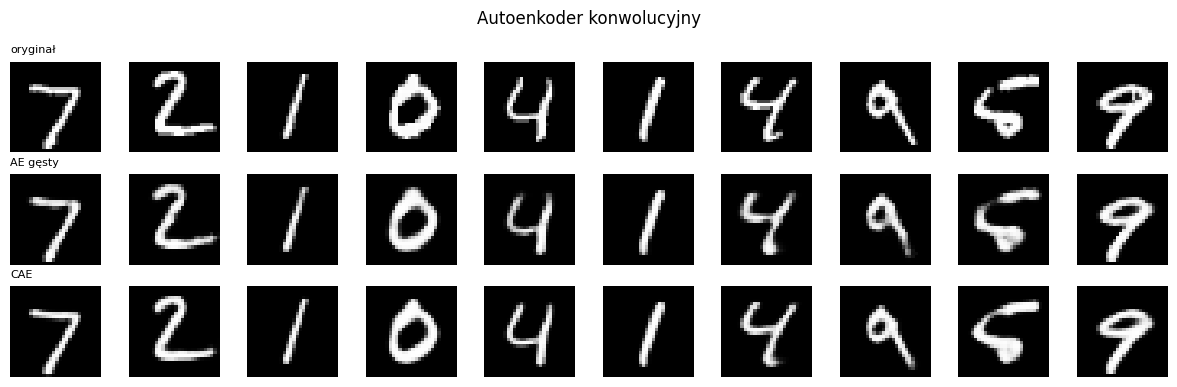

MSE: AE gęsty 32 = 0.005452360492199659 (1,083,696 param.) | CAE 32 = 0.003608847502619028 (278,369 param.)


In [61]:
cae.fit(x_train_img,x_train_img,epochs=EPOKI,batch_size=BATCH,
        validation_split=.1,verbose=0)
rek_cae=cae.predict(x_test_img,verbose=0)
mse_cae32=float(mse_per_sample(x_test_img,rek_cae).mean())
pokaz_rekonstrukcje(x_test_img[:10],[rek_ae32[:10],rek_cae[:10]],
    tytuly=("oryginał","AE gęsty","CAE"),suptitle="Autoenkoder konwolucyjny")
print(f"MSE: AE gęsty 32 = {mse_ae32} ({ae32.count_params():,} param.) | CAE 32 = {mse_cae32} ({cae.count_params():,} param.)")

## 10. Detekcja anomalii błędem rekonstrukcji

**Idea (W5):** autoenkoder wytrenowany wyłącznie na danych "normalnych" dobrze odtwarza to, co zna, a słabo - obiekty nietypowe. Błąd rekonstrukcji $e(\mathbf{x}) = \lVert \mathbf{x} - \hat{\mathbf{x}} \rVert^2$ jest więc **wskaźnikiem anomalii**. Zastosowania: wykrywanie defektów produkcyjnych, nadużyć, awarii czujników - wszędzie tam, gdzie przykładów anomalii jest bardzo mało lub nie znamy ich z góry.

Scenariusz: cyfra **9** to "anomalia". Trenujemy AE na cyfrach 0-8, a następnie oceniamy, czy błąd rekonstrukcji odróżnia 9 od reszty.

Ocena (W4): ponieważ $e(\mathbf{x})$ jest ciągłym wynikiem, liczymy **ROC-AUC**. Próg decyzyjny wybieramy **bez użycia anomalii** - np. 95. percentyl błędu na walidacyjnych danych normalnych (oczekujemy wtedy ok. 5% fałszywych alarmów).

Uwaga merytoryczna: 9 jest podobna do 4 i 7, więc to trudny przypadek - AE może całkiem nieźle zrekonstruować 9. Warto porównać z inną klasą anomalii (Zadanie dodatkowe).

### Zadanie 10.1 - AE jako detektor anomalii

1. Z `x_train_flat` wybierz tylko cyfry różne od `ANOMALIA` (`x_norm`). Odłóż 10% z nich jako walidację (`x_norm_val`).
2. Wytrenuj AE gęsty (latent 16) tylko na `x_norm`.
3. Policz błąd rekonstrukcji dla wszystkich obrazów testowych (`err_test`) i etykietę binarną `y_anom = (y_test == ANOMALIA)`.
4. Policz ROC-AUC, narysuj histogram błędów dla normalnych i anomalii oraz krzywą ROC.
5. Wyznacz próg jako 95. percentyl błędu na `x_norm_val`; policz precision, recall i F1 dla wykrywania anomalii.

**Kryteria sukcesu:** ROC-AUC wyraźnie > 0.5 (w pełnym trybie ok. 0.8-0.9 dla cyfry 9); histogramy anomalii przesunięte w prawo.

Próg: 0.02176336944103241 precision: 0.12718204488778054 recall: 0.05054509415262636 F1: 0.07234042553191489


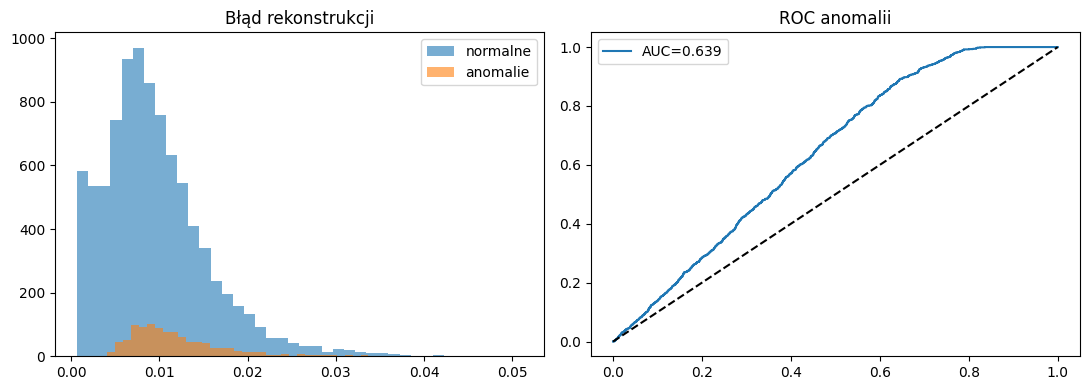

ROC-AUC detekcji anomalii: 0.6388672562001491


In [62]:
ANOMALIA=9
x_norm=x_train_flat[y_train!=ANOMALIA]
x_norm_train,x_norm_val=train_test_split(x_norm,test_size=.1,random_state=SEED)
ae_anom,_,_=zbuduj_ae_gesty(16,nazwa="ae_anom")
ae_anom.fit(x_norm_train,x_norm_train,epochs=EPOKI,batch_size=BATCH,
    validation_data=(x_norm_val,x_norm_val),verbose=0)
err_test=mse_per_sample(x_test_flat,ae_anom.predict(x_test_flat,verbose=0))
y_anom=(y_test==ANOMALIA).astype(int)
auc_anom=roc_auc_score(y_anom,err_test)
err_val=mse_per_sample(x_norm_val,ae_anom.predict(x_norm_val,verbose=0))
prog_anom=float(np.percentile(err_val,95))
yp_anom=(err_test>=prog_anom).astype(int)
from sklearn.metrics import precision_score,recall_score,f1_score,roc_curve
print("Próg:",prog_anom,"precision:",precision_score(y_anom,yp_anom,zero_division=0),
   "recall:",recall_score(y_anom,yp_anom),"F1:",f1_score(y_anom,yp_anom))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(err_test[y_anom==0],bins=40,alpha=.6,label="normalne")
ax[0].hist(err_test[y_anom==1],bins=40,alpha=.6,label="anomalie")
ax[0].legend();ax[0].set_title("Błąd rekonstrukcji")
fpr,tpr,_=roc_curve(y_anom,err_test)
ax[1].plot(fpr,tpr,label=f"AUC={auc_anom:.3f}");ax[1].plot([0,1],[0,1],"k--")
ax[1].legend();ax[1].set_title("ROC anomalii")
plt.tight_layout();plt.show()
print("ROC-AUC detekcji anomalii:", auc_anom)

### Obrazy "najbardziej nietypowe" według AE

Analiza wyników (W4) to nie tylko liczba - warto obejrzeć przypadki skrajne. Poniżej 10 obrazów testowych o największym błędzie rekonstrukcji (z prawdziwą etykietą). Często znajdziesz tu nie tylko dziewiątki, ale też nietypowo napisane cyfry z klas "normalnych" - z punktu widzenia AE to też są anomalie.

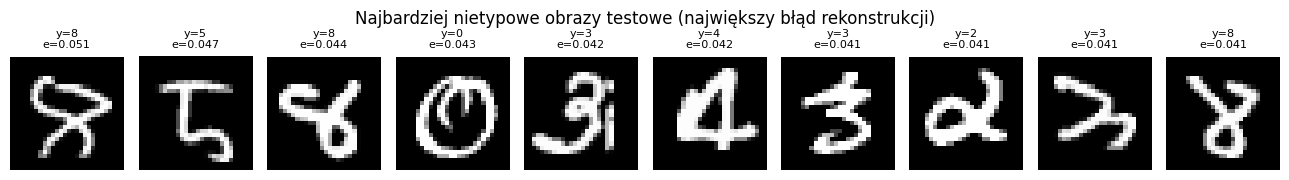

In [63]:
if auc_anom is not None:
    idx = np.argsort(err_test)[::-1][:10]
    fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
    for ax, i in zip(axes, idx):
        ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
        ax.set_title(f"y={y_test[i]}\ne={err_test[i]:.3f}", fontsize=8)
    fig.suptitle("Najbardziej nietypowe obrazy testowe (największy błąd rekonstrukcji)")
    plt.tight_layout(); plt.show()

## Pytania kontrolne

1. Dlaczego LDA może zwrócić co najwyżej $C-1$ wymiarów i czym jej cel różni się od celu PCA?
2. Co oznacza wartość `explained_variance_ratio_` w PCA, a co w LDA?
3. Kiedy wolimy TruncatedSVD od PCA?
4. W jakich warunkach autoenkoder rozpina tę samą podprzestrzeń co PCA? Czy jego wagi są wtedy równe składowym głównym?
5. Dlaczego autoenkoder odszumiający może uczyć się użytecznych cech nawet wtedy, gdy wymiar latentu nie jest mały?
6. Dlaczego silhouette nie nadaje się do porównywania klasteryzacji wykonanych w przestrzeniach o różnym wymiarze? Czym różnią się ARI/NMI od silhouette?
7. Jaki kształt wyjścia da `Conv2DTranspose(16, kernel_size=4, strides=2, padding="valid")` dla wejścia 7x7?
8. Jak należy wybrać próg w detekcji anomalii, aby nie popełnić wycieku danych? Podaj przykład klasy, dla której metoda błędu rekonstrukcji może zawieść.

### Odpowiedzi na pytania kontrolne

**1. LDA i limit $C-1$.** W klasycznej nadzorowanej LDA macierz rozrzutu **międzyklasowego** ma rząd najwyżej $C-1$ dla $C$ klas, dlatego można uzyskać maksymalnie $C-1$ kierunków dyskryminacyjnych (i nie więcej niż liczba cech). **PCA** maksymalizuje całkowitą wariancję danych **bez etykiet**, a **LDA** szuka kierunków dobrze **rozdzielających znane klasy**, uwzględniając relację rozrzutu między klasami i wewnątrz klas.

**2. `explained_variance_ratio_` w PCA i LDA.** W **PCA** jest to udział **całkowitej wariancji danych** wyjaśnianej przez daną składową. W **LDA (`LinearDiscriminantAnalysis`)** opisuje udział **informacji/rozrzutu dyskryminacyjnego między klasami** reprezentowanego przez odpowiedni kierunek; nie należy go interpretować jako udziału całkowitej wariancji danych analogicznie do PCA.

**3. TruncatedSVD zamiast PCA.** Preferujemy je przy **dużych, rzadkich macierzach** (np. dokumenty TF-IDF). `TruncatedSVD` może działać bez centrowania cech, które w PCA zwykle powoduje utratę rzadkości macierzy i duże zużycie pamięci.

**4. Liniowy AE a PCA.** Dla **liniowego autoenkodera z wąskim gardłem**, uczonego przez minimalizację **MSE rekonstrukcji** na odpowiednio wycentrowanych danych, przy spełnieniu warunków optymalności uzyskana podprzestrzeń może być tą samą główną podprzestrzenią, co w PCA. Wagi enkodera **nie muszą być równe** konkretnym wektorom PCA: w przestrzeni latentnej dopuszczalne są zmiany bazy (np. obroty i skalowania skompensowane w dekoderze).

**5. Denoising AE bez małego bottlenecku.** Sieć otrzymuje **zaszumione wejście**, ale ma odtworzyć **czyste dane**. Ten cel wymusza uczenie się regularności i odporności na zakłócenia, a nie tylko kopiowanie wejścia; samo odszumianie stanowi ograniczenie/regularizację nawet przy szerokiej reprezentacji latentnej.

**6. Silhouette, ARI, NMI.** **Silhouette** opiera się na odległościach wewnątrz i pomiędzy klastrami w wybranej przestrzeni. Wymiary i geometria różnych reprezentacji zmieniają rozkłady odległości, więc wartości silhouette **nie są bezpośrednio porównywalne** między takimi przestrzeniami bez dodatkowej kontroli. **ARI i NMI** mierzą zgodność przydziałów do klastrów z **etykietami referencyjnymi**, a nie wewnętrzną geometrię klastrów. ARI uwzględnia korektę o przypadkową zgodność, NMI używa znormalizowanej informacji wzajemnej.

**7. Conv2DTranspose.** Dla wejścia przestrzennego `7x7`, `kernel_size=4`, `strides=2`, `padding='valid'` i domyślnego braku `output_padding` rozmiar przestrzenny wyjścia to $(7-1)\cdot2+4=16$, czyli **`(16,16,16)`** bez wymiaru batcha (16 filtrów/kanałów wyjścia).

**8. Próg anomalii bez wycieku i przypadek porażki.** Uczymy autoenkoder **wyłącznie na normalnych danych treningowych**. Próg wybieramy na **oddzielonej walidacji** (np. 95. percentyl błędu rekonstrukcji wśród normalnych), a test trzymamy nietknięty do oceny końcowej. Metoda może zawieść, gdy anomalia jest **dobrze rekonstruowana**, np. autoenkoder nauczony na cyfrze 0 potrafi równie dobrze odtwarzać podobne nietypowe kształty lub gdy model jest zbyt pojemny i odtwarza również obce klasy.


## Podsumowanie - co warto zapamiętać

- **PCA** = optymalna liniowa kompresja w sensie MSE; wykres skumulowanej wyjaśnionej wariancji mówi, ile składowych potrzeba. Dopasowujemy wyłącznie na zbiorze treningowym.
- **TruncatedSVD** nie centruje danych - stosujemy go do macierzy rzadkich. **LDA jest nadzorowana** i daje maksymalnie $C-1$ wymiarów.
- **Autoenkoder** = enkoder + wąskie gardło + dekoder, uczony `fit(x, x)`. Nieliniowy AE rekonstruuje lepiej niż PCA przy tym samym wymiarze; **liniowy AE z MSE ≈ PCA** (ta sama podprzestrzeń).
- Przestrzeń latentna AE jest często lepsza do **klasteryzacji** niż surowe piksele; oceniamy ARI/NMI (z etykietami) i silhouette (bez etykiet, ostrożnie przy porównaniach).
- **DAE** uczy się `szum -> czysty obraz` i dzięki temu uczy się struktury danych (idea bliska modelom dyfuzyjnym).
- **AE konwolucyjny** używa `Conv2D` ze stride do zwijania i `Conv2DTranspose` do rozwijania; jest dokładniejszy i ma mniej parametrów niż AE gęsty.
- **Detekcja anomalii** błędem rekonstrukcji działa, gdy anomalie są "trudne do odtworzenia"; próg wybieramy tylko na danych normalnych.

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu (zwięźle, 1-2 strony):
1. Wykres skumulowanej wyjaśnionej wariancji PCA z zaznaczonymi $k_{90\%}$ i $k_{95\%}$ oraz porównanie 2D PCA / LDA z komentarzem o różnicy nadzorowana vs nienadzorowana.
2. Wykres MSE(d) AE vs PCA (Zadanie 5.1) - **sformułowana hipoteza i wniosek**, czy się potwierdziła (UGŁ_U01).
3. Tabelę klasteryzacji (Zadanie 7.1) z interpretacją: która przestrzeń jest najlepsza i dlaczego.
4. Wynik detekcji anomalii (ROC-AUC, histogram) dla co najmniej jednej klasy anomalii i krótką dyskusję ograniczeń.
5. Jedną **propozycję usprawnienia** (UGŁ_U02), np. CAE zamiast AE gęstego w detekcji anomalii, inna strata, regularyzacja latentu - najlepiej sprawdzoną eksperymentalnie.

## Zadanie dodatkowe (dla chętnych) - autoenkoder rzadki i porównanie klas anomalii

**Część A - autoenkoder rzadki (sparse AE).** Zamiast wąskiego gardła stosujemy **szeroki** latent (np. 128), ale karzemy aktywacje regularyzacją L1: $\mathcal{L} = \mathcal{L}_{rek} + \lambda \sum_j |z_j|$ (`activity_regularizer=keras.regularizers.L1(λ)`, aktywacja latentu ReLU). Wytrenuj dwa modele: $\lambda = 0$ i $\lambda = 10^{-4}$. Porównaj odsetek neuronów latentu aktywnych (> 0.01) dla średniego obrazu i MSE rekonstrukcji.

**Część B - która cyfra jest najłatwiejsza do wykrycia jako anomalia?** Powtórz Zadanie 10.1 dla anomalii 0, 1 i 9 (krótszy trening) i zestaw ROC-AUC w tabeli.

**Kryteria sukcesu:** w modelu z L1 odsetek aktywnych neuronów wyraźnie spada przy niewielkim wzroście MSE; tabela AUC dla trzech klas z komentarzem.

In [64]:
wyniki_rzadkie, wyniki_anom = [], []
for lam in [0.0,1e-4]:
    we=keras.Input(shape=(784,))
    h=layers.Dense(256,activation="relu")(we)
    z=layers.Dense(128,activation="relu",name="sparse_latent",
        activity_regularizer=keras.regularizers.L1(lam) if lam else None)(h)
    h=layers.Dense(256,activation="relu")(z)
    wy=layers.Dense(784,activation="sigmoid")(h)
    model_s=keras.Model(we,wy)
    enc_s=keras.Model(we,z)
    model_s.compile(optimizer="adam",loss="binary_crossentropy")
    model_s.fit(x_train_flat,x_train_flat,epochs=EPOKI_KROTKO,batch_size=BATCH,verbose=0)
    sredni_obraz = x_train_flat.mean(axis=0, keepdims=True)
    z_s=enc_s.predict(sredni_obraz,verbose=0)
    wyniki_rzadkie.append({"L1":lam,"odsetek_aktywnych":float((z_s>.01).mean()),
       "MSE":float(mse_per_sample(x_test_flat,model_s.predict(x_test_flat,verbose=0)).mean())})
for anom in [0,1,9]:
    x_n=x_train_flat[y_train!=anom]
    ae_a,_,_=zbuduj_ae_gesty(16,nazwa=f"ae_anom_{anom}")
    ae_a.fit(x_n,x_n,epochs=EPOKI_KROTKO,batch_size=BATCH,verbose=0)
    e=mse_per_sample(x_test_flat,ae_a.predict(x_test_flat,verbose=0))
    wyniki_anom.append({"cyfra":anom,"ROC_AUC":roc_auc_score((y_test==anom).astype(int),e)})
display(pd.DataFrame(wyniki_rzadkie).round(4))
display(pd.DataFrame(wyniki_anom).round(3))

,L1,odsetek_aktywnych,MSE
0,0.0000,0.8672,0.0040
1,0.0001,0.0000,0.0675


,cyfra,ROC_AUC
0,0,0.961
1,1,0.307
2,9,0.690
